# Módelo de Regresión Lineal
**Steffany Mishell Lara Muy** -
**A00838589**





In [3]:
from typing_extensions import dataclass_transform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seabornInstance
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
%matplotlib inline

#import el csv
dataset=pd.read_csv('score_updated.csv')
dataset.shape
dataset.describe()

,Hours,Scores
count,96.000000,96.000000
mean,5.267708,54.020833
std,2.503030,25.017459
min,1.000000,12.000000
25%,3.075000,30.750000
50%,5.250000,54.500000
75%,7.325000,74.250000
max,9.800000,99.000000


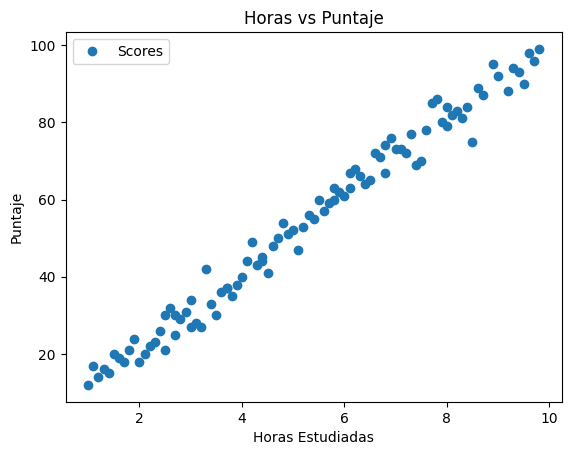

In [4]:
dataset.plot(x='Hours',y='Scores',style='o') #para graficar los datos que tengo
plt.title('Horas vs Puntaje')
plt.xlabel('Horas Estudiadas')
plt.ylabel('Puntaje')
plt.show()


<ipython-input-5-5cf9f151fc68>:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  seabornInstance.distplot(dataset['Scores'])


<Axes: xlabel='Scores', ylabel='Density'>

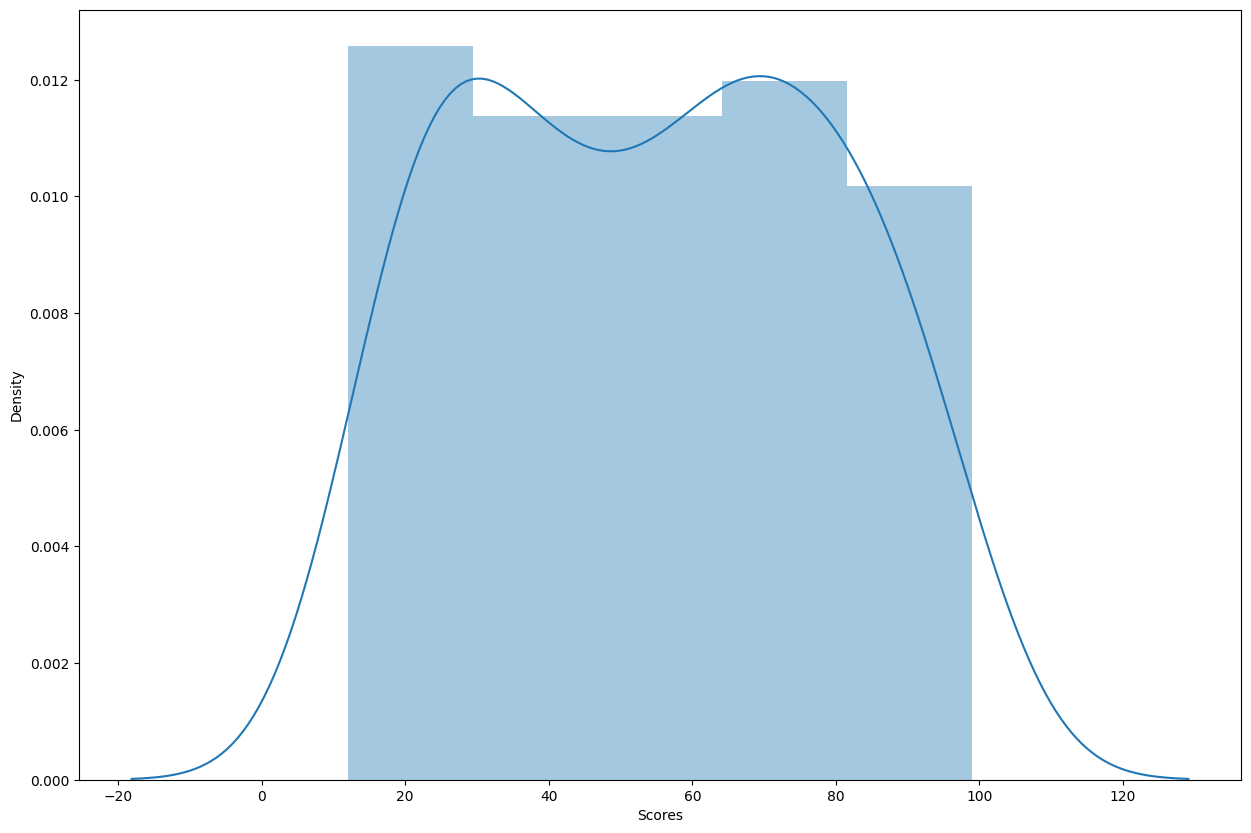

In [5]:
plt.figure(figsize=(15,10)) #grafico para ver como tienden las notas
plt.tight_layout()
seabornInstance.distplot(dataset['Scores'])


In [6]:
X = dataset['Hours'].values.reshape(-1,1)
y = dataset['Scores'].values.reshape(-1,1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)#20% sera usado para test
regressor = LinearRegression()
regressor.fit(X_train, y_train) #algoritmo que entrena
#para ver cual es el intercepto
print(regressor.intercept_)

#la pendiente
print(regressor.coef_)
y_pred = regressor.predict(X_test)
df = pd.DataFrame({'Actual': y_test.flatten(), 'Predicted': y_pred.flatten()})
df

[1.56551359]
[[9.94599746]]


,Actual,Predicted
0,90,96.052489
1,40,41.349503
2,27,33.392705
3,48,47.317102
4,74,69.198296
5,72,73.176695
6,30,26.430507
7,57,57.263099
8,26,25.435907
9,15,15.489910


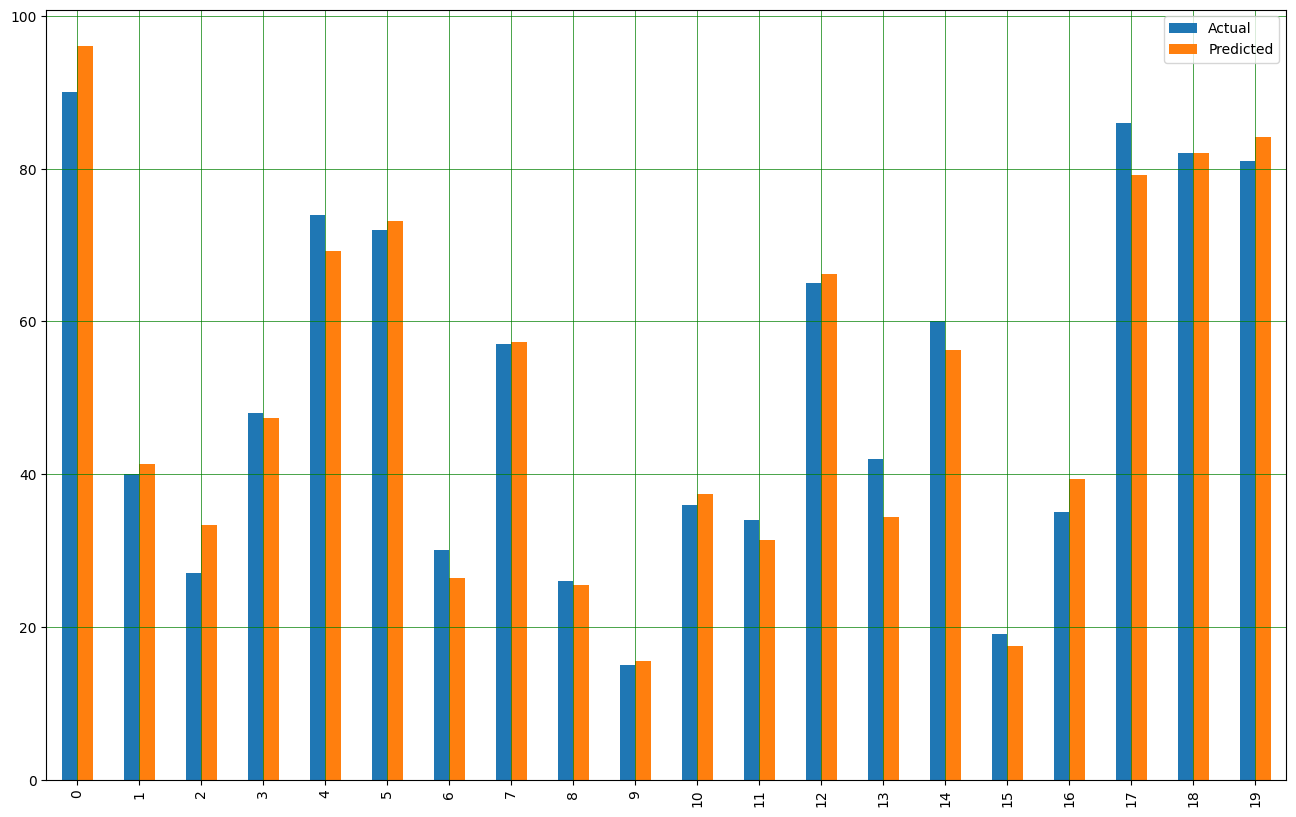

In [7]:
#Comparar con los datos reales
df1 = df.head(25)
df1.plot(kind='bar',figsize=(16,10))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

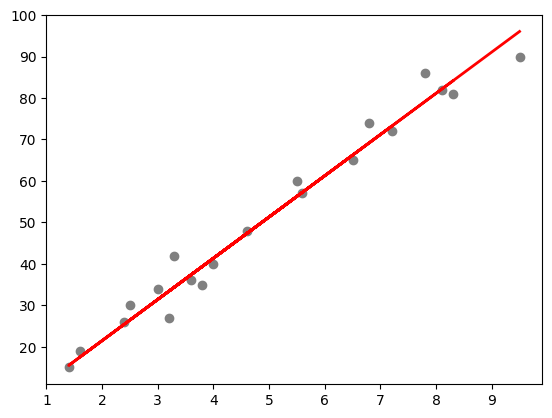

In [8]:
plt.scatter(X_test, y_test,  color='gray')#grafico el testttt
plt.plot(X_test, y_pred, color='red', linewidth=2)
plt.show()

In [9]:
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))#veo que tan preciso es con estos errores
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error: 2.8925583517538658
Mean Squared Error: 13.881520927483502
Root Mean Squared Error: 3.725791315611155


EAl realizar este tutorial me enfoqué primero en entender bien el dataset que estaba utilizando. Para esto tomé la decisión de revisar su estructura y características con funciones como describe() y shape, que son fundamentales para familiarizarse rápidamente con los datos. Luego decidí generar gráficas iniciales, histogramas y scatter plots, ya que me interesaba visualizar cómo se distribuían las variables clave, sobre todo la relación entre las horas de estudio y el puntaje obtenido por los estudiantes. Al observar que esta relación era bastante lineal, opté por utilizar un modelo de regresión lineal sencillo.

Cuando dividí el dataset en entrenamiento y prueba usando train_test_split me aseguré que hubiera suficiente balance, lo cual tambien es esencial para prevenir sobreajuste. Aunque ajustar el modelo con LinearRegression no me presentó dificultades mayores, sí experimenté algunos retos al momento de interpretar las métricas de desempeño, especialmente el MAE y el R2, porque al inicio me confundía un poco cuál representaba mejor la calidad del modelo en este contexto específico.

Finalmente, comprendí que un análisis preliminar bien hecho, donde te tomás el tiempo de explorar cuidadosamente los datos y visualizar tendencias claras, simplifica enormemente las decisiones posteriores durante el modelado. Además aprendí que documentar cada etapa, aunque parezca tedioso, realmente ayuda a mantener claridad y facilitar interpretaciones correctas, sobre todo cuando más adelante necesitas justificar lo que haces, en multiples ocasiones mi codigo no funcionaba y como no tenía un backup de la versión eficiente tocaba hacer todo de 0.